In [1]:
import numpy as np
import pandas as pd
import nibabel as nib
from scipy.spatial.distance import euclidean

import torch
from sklearn.model_selection import KFold
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
def model_FC(W, steps):
    
    sim_pre = [np.zeros(W.shape[0])]; random_noise_pre = 0.1 * np.random.randn(100, W.shape[0])
    for i in range(1, 100): sim_pre.append(W @ sim_pre[-1] + random_noise_pre[i])
    sim_post = [sim_pre[-1]]; random_noise_post = 0.1 * np.random.randn(steps, W.shape[0])
    for i in range(1, steps): sim_post.append(W @ sim_post[-1] + random_noise_post[i])
    sim_post = np.array(sim_post)
    
    return np.corrcoef(sim_post.T)

In [3]:
def flat_without_diagonal(matrix):

    matrix = matrix.copy()
    n = matrix.shape[0]
    upper = matrix[np.triu_indices(n, k =  1)]
    lower = matrix[np.tril_indices(n, k = -1)]
    
    return np.concatenate([upper, lower])

In [4]:
class RidgeNN(torch.nn.Module):

    def __init__(self, n_features, alpha, weight_matrix):
        super(RidgeNN, self).__init__()
        self.linear = torch.nn.Linear(n_features, n_features, bias = False)
        self.n_features = n_features
        self.alpha = alpha
        self.weight_matrix = weight_matrix

    def forward(self, X):
        return self.linear(X)

    def loss(self, X, y):
        y_pred = self.forward(X)
        sse_loss = torch.sum((y_pred - y) ** 2)
        weighted_l2_reg = self.alpha * torch.sum(self.weight_matrix * (self.linear.weight ** 2))
        return sse_loss + weighted_l2_reg

def train_NN(model, X_train, y_train, num_epochs = 100, lr = 0.01):

    trainer = torch.optim.Adam(model.parameters(), lr = lr)

    for _ in range(num_epochs):
        
        model.train()
        l = model.loss(X_train, y_train)
        trainer.zero_grad()
        l.backward()
        trainer.step()
            
    return model

In [5]:
atlas_gii_surf_L = nib.load('./inputs/S1200.L.pial_MSMAll.10k_fs_LR.surf.gii').darrays[0].data
atlas_gii_surf_R = nib.load('./inputs/S1200.R.pial_MSMAll.10k_fs_LR.surf.gii').darrays[0].data
atlas_gii_surf = np.vstack([atlas_gii_surf_L, atlas_gii_surf_R])
atlas_gii_label_L = nib.load('./inputs/L.Glasser2016.human.10k_fs_LR.label.gii').darrays[0].data
atlas_gii_label_R = nib.load('./inputs/R.Glasser2016.human.10k_fs_LR.label.gii').darrays[0].data
atlas_gii_label_R[atlas_gii_label_R != 0] += 1000
atlas_gii_label = np.hstack([atlas_gii_label_L, atlas_gii_label_R])
roi_labels = np.unique(atlas_gii_label); roi_labels = sorted(roi_labels[roi_labels != 0])
centroids = [np.mean(atlas_gii_surf[np.argwhere(atlas_gii_label == label).flatten()], axis = 0) for label in roi_labels]

distance = np.zeros((len(roi_labels), len(roi_labels)))
distance = np.array([[euclidean(centroids[i], centroids[j]) for j in range(len(roi_labels))] for i in range(len(roi_labels))])

#### fit example data for $\lambda=0.7$

In [6]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

In [7]:
sub = '118730'
lam = 0.7

kf_shuffle = KFold(n_splits = 5, shuffle = True)
kf_raw = KFold(n_splits = 5, shuffle = False)

weight_matrix = distance.copy()
weight_matrix /= np.mean(flat_without_diagonal(weight_matrix))
np.fill_diagonal(weight_matrix, 1)
weight_matrix = torch.tensor(weight_matrix, dtype = torch.float32).to(device)

ts_list = [np.loadtxt('./inputs/' + sub + '_REST' + append + '.txt')[:, :360] for append in ['1_LR', '1_RL', '2_LR', '2_RL']]
empiricalFC = np.corrcoef(np.vstack(ts_list).T)
X = np.vstack([ts[:-1] for ts in ts_list]); y = np.vstack([ts[1:] for ts in ts_list])
X_train_numpy, X_test_numpy, y_train_numpy, y_test_numpy = train_test_split(X, y, test_size = 0.2)
X_train_tensor = torch.tensor(X_train_numpy, dtype = torch.float32).to(device); y_train_tensor = torch.tensor(y_train_numpy, dtype = torch.float32).to(device)
X_test_tensor = torch.tensor(X_test_numpy, dtype = torch.float32).to(device); y_test_tensor = torch.tensor(y_test_numpy, dtype = torch.float32).to(device)

alpha = lam/(1-lam) * X_train_numpy.shape[0]
model = RidgeNN(n_features = X.shape[1], alpha = alpha, weight_matrix = weight_matrix).to(device)
model = train_NN(model, X_train_tensor, y_train_tensor, num_epochs = 500, lr = 0.01)
estimatedEC = model.linear.weight.data.cpu().numpy()
modelFC = model_FC(model.linear.weight.data.cpu().numpy(), steps = 10000)

r2_5fold_raw = []
for train_index, test_index in kf_raw.split(X):
    X_train_numpy, X_test_numpy, y_train_numpy, y_test_numpy = X[train_index], X[test_index], y[train_index], y[test_index]
    X_train_tensor = torch.tensor(X_train_numpy, dtype = torch.float32).to(device); y_train_tensor = torch.tensor(y_train_numpy, dtype = torch.float32).to(device)
    X_test_tensor = torch.tensor(X_test_numpy, dtype = torch.float32).to(device); y_test_tensor = torch.tensor(y_test_numpy, dtype = torch.float32).to(device)
    alpha = lam/(1-lam) * X_train_numpy.shape[0]
    model = RidgeNN(n_features = X.shape[1], alpha = alpha, weight_matrix = weight_matrix).to(device)
    model = train_NN(model, X_train_tensor, y_train_tensor, num_epochs = 500, lr = 0.01)
    r2_test = r2_score(y_test_numpy, model(X_test_tensor).detach().cpu().numpy())
    r2_5fold_raw.append(r2_test)

print('Prediction R^2: {:.3f}'.format(np.mean(np.array(r2_5fold_raw))))
print('Model - empirical FC corr: {:.3f}'.format(np.corrcoef(flat_without_diagonal(empiricalFC), flat_without_diagonal(modelFC))[0, 1]))

Prediction R^2: 0.692
Model - empirical FC corr: 0.954


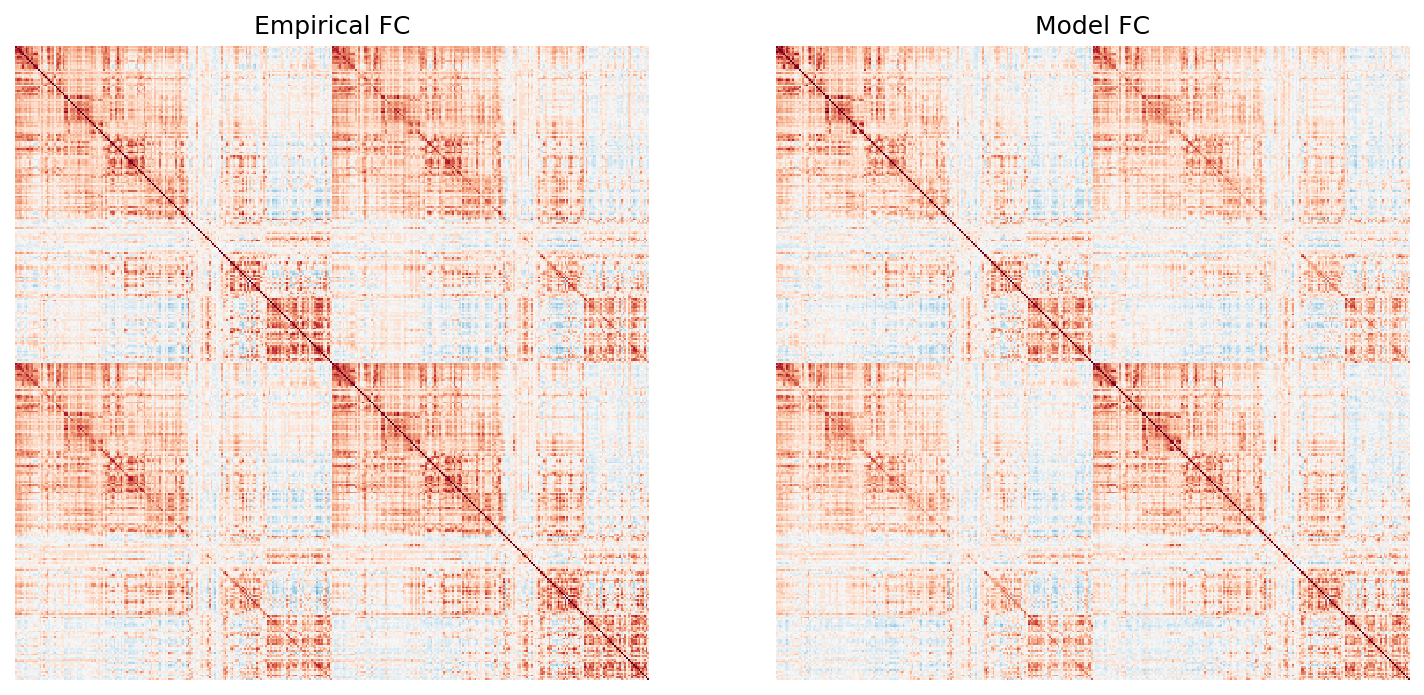

In [8]:
neworderlr = np.loadtxt('./inputs/neworderlr.txt')
neworder = np.array([np.where(neworderlr == i)[0][0] for i in range(len(neworderlr))])
oldorder = np.array([np.where(neworder == i)[0][0] for i in range(len(neworder))])

plt.rcParams['figure.dpi'] = 150
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (12, 6))
sns.heatmap(empiricalFC[neworder].T[neworder].T, ax = ax1, vmin = -1.0, vmax = 1.0, cmap = 'RdBu_r', cbar = False, square = True, xticklabels = False, yticklabels = False)
sns.heatmap(modelFC[neworder].T[neworder].T, ax = ax2, vmin = -0.25, vmax = 0.25, cmap = 'RdBu_r', cbar = False, square = True, xticklabels = False, yticklabels = False)
ax1.set_title('Empirical FC'); ax2.set_title('Model FC')
plt.show()

#### fit example data for all $\lambda$

In [9]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

In [10]:
sub = '118730'

lambdas = np.linspace(0.02, 0.98, 49)

kf_shuffle = KFold(n_splits = 5, shuffle = True)
kf_raw = KFold(n_splits = 5, shuffle = False)

weight_matrix = distance.copy()
weight_matrix /= np.mean(flat_without_diagonal(weight_matrix))
np.fill_diagonal(weight_matrix, 1)
weight_matrix = torch.tensor(weight_matrix, dtype = torch.float32).to(device)

res_data = {'FILE_ID': [], 'lambda': [], 'R2_train': [], 'R2_test': [], 'R2_5fold(shuffle)': [], 'R2_5fold(raw)':[], 'FC_recon': []}

ts_list = [np.loadtxt('./inputs/' + sub + '_REST' + append + '.txt')[:, :360] for append in ['1_LR', '1_RL', '2_LR', '2_RL']]
empirical_FC = np.corrcoef(np.vstack(ts_list).T)
X = np.vstack([ts[:-1] for ts in ts_list]); y = np.vstack([ts[1:] for ts in ts_list])
X_train_numpy, X_test_numpy, y_train_numpy, y_test_numpy = train_test_split(X, y, test_size = 0.2)
X_train_tensor = torch.tensor(X_train_numpy, dtype = torch.float32).to(device); y_train_tensor = torch.tensor(y_train_numpy, dtype = torch.float32).to(device)
X_test_tensor = torch.tensor(X_test_numpy, dtype = torch.float32).to(device); y_test_tensor = torch.tensor(y_test_numpy, dtype = torch.float32).to(device)

for l in lambdas:
    alpha = l/(1-l) * X_train_numpy.shape[0]
    model = RidgeNN(n_features = X.shape[1], alpha = alpha, weight_matrix = weight_matrix).to(device)
    model = train_NN(model, X_train_tensor, y_train_tensor, num_epochs = 500, lr = 0.01)
    np.savez_compressed('./outputs/{}_{:02d}.npz'.format(sub, round(l*100)), model.linear.weight.data.cpu().numpy())
    r2_train = r2_score(y_train_numpy, model(X_train_tensor).detach().cpu().numpy()); r2_test = r2_score(y_test_numpy, model(X_test_tensor).detach().cpu().numpy())
    FC_recon = np.corrcoef(flat_without_diagonal(model_FC(model.linear.weight.data.cpu().numpy(), steps = 10000)), flat_without_diagonal(empirical_FC))[0, 1]
    res_data['FILE_ID'].append(sub); res_data['lambda'].append(l); res_data['R2_train'].append(r2_train); res_data['R2_test'].append(r2_test); res_data['FC_recon'].append(FC_recon)
    
r2_5fold_shuffle = []
for train_index, test_index in kf_shuffle.split(X):
    X_train_numpy, X_test_numpy, y_train_numpy, y_test_numpy = X[train_index], X[test_index], y[train_index], y[test_index]
    X_train_tensor = torch.tensor(X_train_numpy, dtype = torch.float32).to(device); y_train_tensor = torch.tensor(y_train_numpy, dtype = torch.float32).to(device)
    X_test_tensor = torch.tensor(X_test_numpy, dtype = torch.float32).to(device); y_test_tensor = torch.tensor(y_test_numpy, dtype = torch.float32).to(device)
    r2_test_list = []
    for l in lambdas:
        alpha = l/(1-l) * X_train_numpy.shape[0]
        model = RidgeNN(n_features = X.shape[1], alpha = alpha, weight_matrix = weight_matrix).to(device)
        model = train_NN(model, X_train_tensor, y_train_tensor, num_epochs = 500, lr = 0.01)
        r2_test = r2_score(y_test_numpy, model(X_test_tensor).detach().cpu().numpy())
        r2_test_list.append(r2_test)
    r2_5fold_shuffle.append(r2_test_list)
r2_5fold_shuffle = np.array(r2_5fold_shuffle)
for l in lambdas: res_data['R2_5fold(shuffle)'].append(np.mean(r2_5fold_shuffle, axis = 0)[np.where(abs(lambdas-l)<1e-10)[0][0]])

r2_5fold_raw = []
for train_index, test_index in kf_raw.split(X):
    X_train_numpy, X_test_numpy, y_train_numpy, y_test_numpy = X[train_index], X[test_index], y[train_index], y[test_index]
    X_train_tensor = torch.tensor(X_train_numpy, dtype = torch.float32).to(device); y_train_tensor = torch.tensor(y_train_numpy, dtype = torch.float32).to(device)
    X_test_tensor = torch.tensor(X_test_numpy, dtype = torch.float32).to(device); y_test_tensor = torch.tensor(y_test_numpy, dtype = torch.float32).to(device)
    r2_test_list = []
    for l in lambdas:
        alpha = l/(1-l) * X_train_numpy.shape[0]
        model = RidgeNN(n_features = X.shape[1], alpha = alpha, weight_matrix = weight_matrix).to(device)
        model = train_NN(model, X_train_tensor, y_train_tensor, num_epochs = 500, lr = 0.01)
        r2_test = r2_score(y_test_numpy, model(X_test_tensor).detach().cpu().numpy())
        r2_test_list.append(r2_test)
    r2_5fold_raw.append(r2_test_list)
r2_5fold_raw = np.array(r2_5fold_raw)
for l in lambdas: res_data['R2_5fold(raw)'].append(np.mean(r2_5fold_raw, axis = 0)[np.where(abs(lambdas-l)<1e-10)[0][0]])

df = pd.DataFrame(res_data); df.to_csv('./outputs/validation_res_HCP_MMP(distance_ridge).csv', index = False)